In [2]:
import pandas as pd 
adult_census = pd.read_csv("../Data/adult.csv")
adult_census = adult_census.drop(columns=["education-num", "fnlwgt"])

target_name = "class"
target = adult_census[target_name]
data = adult_census.drop(columns=target_name)

numerical_columns = ["age", "capital-gain", "capital-loss", "hours-per-week"]
data_numeric = data[numerical_columns]

In [3]:
from sklearn.model_selection import train_test_split

data_numeric_train, data_numeric_test, target_train, target_test = train_test_split(data_numeric, target, random_state=42)
data_numeric_train.describe()

,age,capital-gain,capital-loss,hours-per-week
count,36631.000000,36631.000000,36631.000000,36631.000000
mean,38.642352,1087.077721,89.665311,40.431247
std,13.725748,7522.692939,407.110175,12.423952
min,17.000000,0.000000,0.000000,1.000000
25%,28.000000,0.000000,0.000000,40.000000
50%,37.000000,0.000000,0.000000,40.000000
75%,48.000000,0.000000,0.000000,45.000000
max,90.000000,99999.000000,4356.000000,99.000000


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().set_output(transform="pandas")
scaler.fit(data_numeric_train)
data_train_scaled = scaler.transform(data_numeric_train)
data_test_scaled = scaler.transform(data_numeric_test)

data_train_scaled.describe()

,age,capital-gain,capital-loss,hours-per-week
count,3.663100e+04,3.663100e+04,3.663100e+04,3.663100e+04
mean,-2.246208e-16,1.823347e-17,-4.422586e-17,1.788432e-16
std,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00
min,-1.576792e+00,-1.445084e-01,-2.202513e-01,-3.173852e+00
25%,-7.753674e-01,-1.445084e-01,-2.202513e-01,-3.471139e-02
50%,-1.196565e-01,-1.445084e-01,-2.202513e-01,-3.471139e-02
75%,6.817680e-01,-1.445084e-01,-2.202513e-01,3.677425e-01
max,3.741752e+00,1.314865e+01,1.047970e+01,4.714245e+00


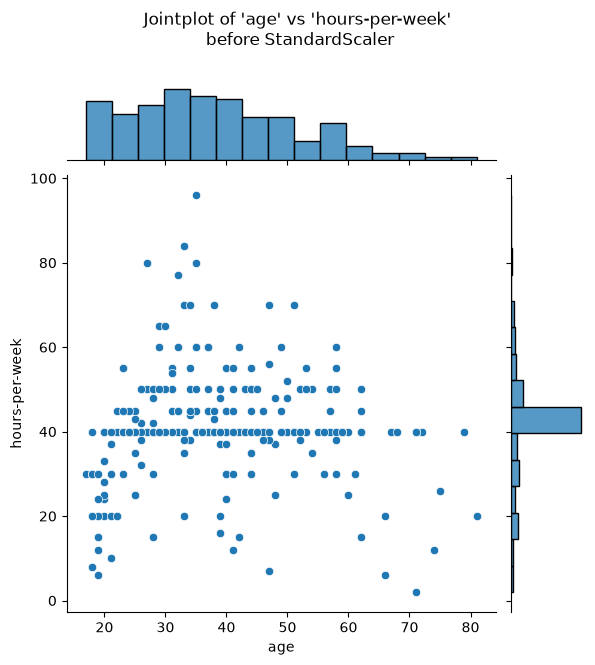

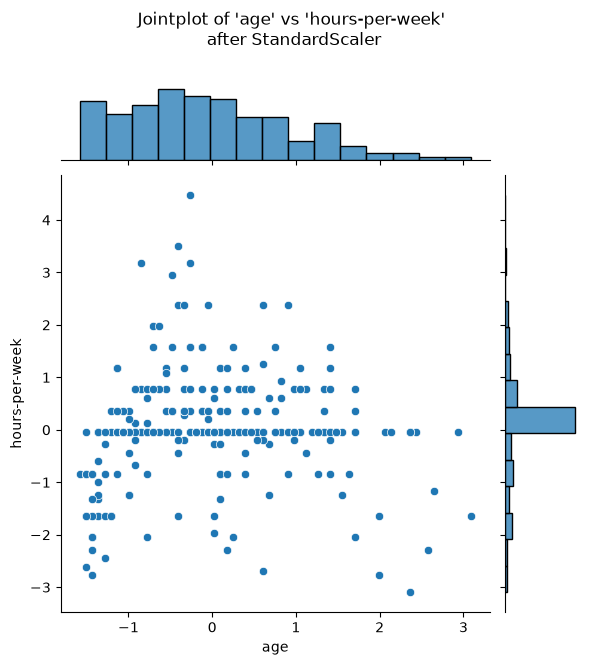

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

num_points_to_plot = 300
sns.jointplot(
    data=data_numeric_train[:num_points_to_plot],
    x="age",
    y="hours-per-week",
    marginal_kws=dict(bins=15)
)
plt.suptitle("Jointplot of 'age' vs 'hours-per-week' \nbefore StandardScaler", y=1.1)

sns.jointplot(
    data=data_train_scaled[:num_points_to_plot],
    x="age",
    y="hours-per-week",
    marginal_kws=dict(bins=15)
)
_ = plt.suptitle("Jointplot of 'age' vs 'hours-per-week' \nafter StandardScaler", y=1.1)

In [19]:
import time 
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler(), LogisticRegression())

start = time.time()
model.fit(data_numeric_train, target_train)
elapsed_time = time.time() - start

predicted_target = model.predict(data_numeric_test)
predicted_target[:5]

array(['<=50K', '<=50K', '>50K', '<=50K', '<=50K'], dtype=object)

In [20]:
model_name = model.__class__.__name__
score = model.score(data_numeric_test, target_test)
print(
    f"The accuracy using a {model_name} is {score:.3f} "
    f"with a fitting time of {elapsed_time:.3f} seconds "
    f"in {model[-1].n_iter_[0]} iterations"
)

The accuracy using a Pipeline is 0.807 with a fitting time of 0.173 seconds in 9 iterations
